In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

x_train, y_train = x_train[:5000]/255.0, y_train[:5000]
x_test, y_test = x_test[:1000]/255.0, y_test[:1000]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (5000, 32, 32, 3)
Testing data: (1000, 32, 32, 3)


In [9]:
layers.AveragePooling2D(pool_size=2)

<AveragePooling2D name=average_pooling2d, built=True>

In [12]:
def create_model(name):
    m = models.Sequential()
    m.add(layers.Input(shape=(32, 32, 3)))

    if name == "LeNet":
        m.add(layers.Conv2D(6, 5, activation='relu', padding='same'))
        m.add(layers.AveragePooling2D(pool_size=2))
        m.add(layers.Conv2D(16, 5, activation='relu'))
        m.add(layers.AveragePooling2D(pool_size=2))
        m.add(layers.Flatten())
        m.add(layers.Dense(120, activation='relu'))
        m.add(layers.Dense(84, activation='relu'))

    elif name == "AlexNet":
        m.add(layers.Conv2D(32, 3, activation='relu', padding='same'))
        m.add(layers.MaxPooling2D(pool_size=2))
        m.add(layers.Conv2D(64, 3, activation='relu', padding='same'))
        m.add(layers.MaxPooling2D(pool_size=2))
        m.add(layers.Conv2D(128, 3, activation='relu', padding='same'))
        m.add(layers.Flatten())
        m.add(layers.Dense(256, activation='relu'))

    elif name == "VGG16":
        for filters in [32, 64, 128]:
            m.add(layers.Conv2D(filters, 3, activation='relu', padding='same'))
            m.add(layers.Conv2D(filters, 3, activation='relu', padding='same'))
            m.add(layers.MaxPooling2D(pool_size=2))

        m.add(layers.Flatten())
        m.add(layers.Dense(256, activation='relu'))

    m.add(layers.Dense(10, activation='softmax'))
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

In [13]:
results = {}
histories = {}

for name in ["LeNet", "AlexNet", "VGG16"]:
    model = create_model(name)

    start = time.time()
    history = model.fit(x_train, y_train, epochs=3,
                        batch_size=64, validation_split=0.2, verbose=1)
    training_time = time.time() - start

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results[name] = [accuracy, training_time]
    histories[name] = history

    print(name, "Accuracy:", round(accuracy*100, 2), "%")
    print("Training time:", round(training_time, 2), "seconds")

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.2142 - loss: 2.1308 - val_accuracy: 0.3060 - val_loss: 1.9067
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3282 - loss: 1.8521 - val_accuracy: 0.3340 - val_loss: 1.8219
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3620 - loss: 1.7511 - val_accuracy: 0.3300 - val_loss: 1.8226
LeNet Accuracy: 36.0 %
Training time: 7.45 seconds
Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.2432 - loss: 2.0648 - val_accuracy: 0.3410 - val_loss: 1.8175
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.4013 - loss: 1.6639 - val_accuracy: 0.4370 - val_loss: 1.6089
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.4615 - loss: 1.4930 - val_accuracy: 0.4460 - val_loss: 1.5606
AlexNet Accuracy: 46.1 %
Training time: 13.42 seconds
Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 111ms/step - accuracy: 0.1713 - loss: 2.2039 - val_accuracy: 0.2850 - val_loss: 1.9617
Epoch 2/3
6

In [14]:
base = tf.keras.applications.ResNet50(
    weights='imagenet', include_top=False,
    input_shape=(96, 96, 3)
)
base.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
x = layers.Resizing(96, 96)(inputs)
x = layers.Rescaling(255.0)(x)
x = layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input
)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x)

resnet = models.Model(inputs, outputs)
resnet.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

start = time.time()
resnet_history = resnet.fit(
    x_train, y_train, epochs=3,
    batch_size=32, validation_split=0.2
)
feature_time = time.time() - start

loss, accuracy = resnet.evaluate(x_test, y_test, verbose=0)
results["ResNet50 Feature Extraction"] = [accuracy, feature_time]

print("ResNet50 Feature Extraction Accuracy:", round(accuracy*100, 2), "%")
print("Training time:", round(feature_time, 2), "seconds")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 84s 578ms/step - accuracy: 0.6787 - loss: 1.1061 - val_accuracy: 0.7890 - val_loss: 0.6525
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 68s 547ms/step - accuracy: 0.8475 - loss: 0.4446 - val_accuracy: 0.8160 - val_loss: 0.6414
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 533ms/step - accuracy: 0.8980 - loss: 0.3022 - val_accuracy: 0.8310 - val_loss: 0.5697
ResNet50 Feature Extraction Accuracy: 80.0 %
Training time: 218.85 seconds


In [15]:
base.trainable = True

for layer in base.layers[:-10]:
    layer.trainable = False

for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

start = time.time()
fine_history = resnet.fit(
    x_train, y_train, epochs=3,
    batch_size=32, validation_split=0.2
)
fine_time = time.time() - start

loss, accuracy = resnet.evaluate(x_test, y_test, verbose=0)
results["ResNet50 Fine-tuning"] = [accuracy, feature_time + fine_time]

print("Fine-tuned ResNet50 Accuracy:", round(accuracy*100, 2), "%")
print("Total training time:", round(feature_time + fine_time, 2), "seconds")

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 93s 638ms/step - accuracy: 0.9503 - loss: 0.1777 - val_accuracy: 0.8320 - val_loss: 0.5851
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 77s 615ms/step - accuracy: 0.9768 - loss: 0.1067 - val_accuracy: 0.8270 - val_loss: 0.5869
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 76s 606ms/step - accuracy: 0.9900 - loss: 0.0691 - val_accuracy: 0.8240 - val_loss: 0.6023
Fine-tuned ResNet50 Accuracy: 81.4 %
Total training time: 470.68 seconds


In [16]:
for name, values in results.items():
    print(name, "Accuracy:", round(values[0]*100, 2),
          "% | Time:", round(values[1], 2), "seconds")

LeNet Accuracy: 36.0 % | Time: 7.45 seconds
AlexNet Accuracy: 46.1 % | Time: 13.42 seconds
VGG16 Accuracy: 36.2 % | Time: 23.64 seconds
ResNet50 Feature Extraction Accuracy: 80.0 % | Time: 218.85 seconds
ResNet50 Fine-tuning Accuracy: 81.4 % | Time: 470.68 seconds


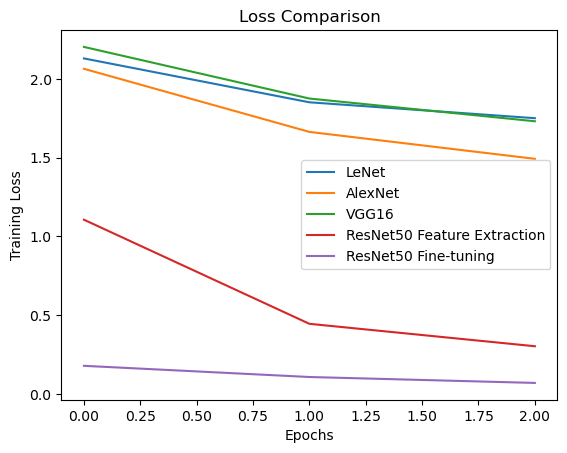

In [17]:
for name, history in histories.items():
    plt.plot(history.history['loss'], label=name)

plt.plot(resnet_history.history['loss'], label='ResNet50 Feature Extraction')
plt.plot(fine_history.history['loss'], label='ResNet50 Fine-tuning')

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Loss Comparison")
plt.legend()
plt.show()

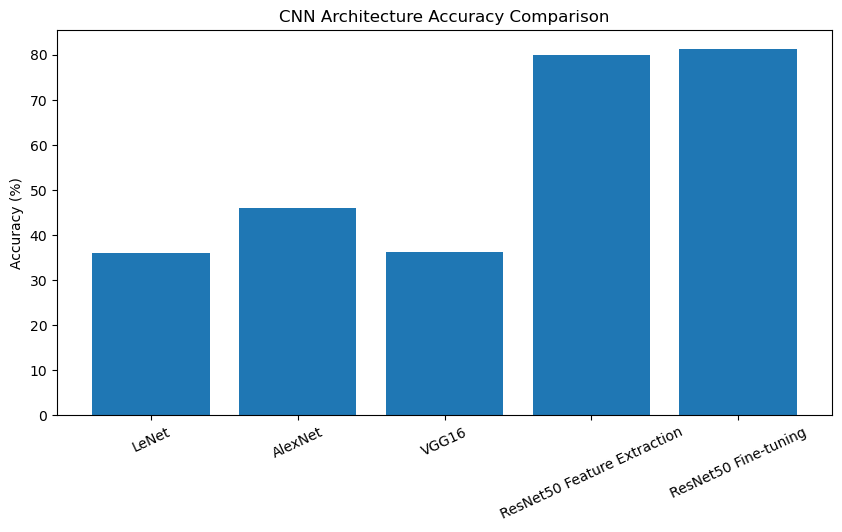

In [18]:
names = list(results.keys())
accuracies = [v[0]*100 for v in results.values()]

plt.figure(figsize=(10, 5))
plt.bar(names, accuracies)
plt.ylabel("Accuracy (%)")
plt.title("CNN Architecture Accuracy Comparison")
plt.xticks(rotation=25)
plt.show()

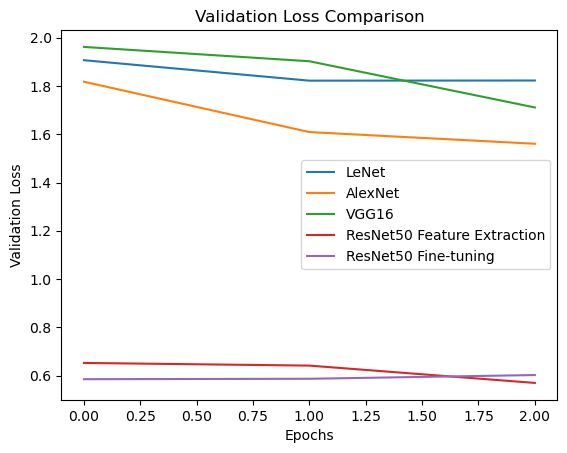

In [19]:
for name, history in histories.items():
    plt.plot(history.history['val_loss'], label=name)

plt.plot(resnet_history.history['val_loss'], label='ResNet50 Feature Extraction')
plt.plot(fine_history.history['val_loss'], label='ResNet50 Fine-tuning')

plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.show()